# Lab3: Stock price prediction
### Réalisé par: Abdelkader Arras
### EMSI 2025/2026


# T.A.F
1. Démarrer 
2. Analyser
3. Améliorer

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM
from keras.layers import Dropout
from keras.layers import Dense

# Step 1: Dataset
 url = 'https://raw.githubusercontent.com/mwitiderrick/stockprice/master/NSE-TATAGLOBAL.csv'

In [5]:
url = 'https://raw.githubusercontent.com/mwitiderrick/stockprice/master/NSE-TATAGLOBAL.csv'
dataset_train = pd.read_csv(url)
training_set = dataset_train.iloc[:, 1:2].values
print(dataset_train.head())
# Data transformation
sc = MinMaxScaler(feature_range=(0,1))
training_set_scaled = sc.fit_transform(training_set)
#print(training_set_scaled)
X_train = []
y_train = []
for i in range(60, 2035):
    X_train.append(training_set_scaled[i-60:i, 0])
    y_train.append(training_set_scaled[i, 0])
X_train, y_train = np.array(X_train), np.array(y_train)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
#print(X_train)


         Date    Open    High     Low    Last   Close  Total Trade Quantity  \
0  2018-09-28  234.05  235.95  230.20  233.50  233.75               3069914   
1  2018-09-27  234.55  236.80  231.10  233.80  233.25               5082859   
2  2018-09-26  240.00  240.00  232.50  235.00  234.25               2240909   
3  2018-09-25  233.30  236.75  232.00  236.25  236.10               2349368   
4  2018-09-24  233.55  239.20  230.75  234.00  233.30               3423509   

   Turnover (Lacs)  
0          7162.35  
1         11859.95  
2          5248.60  
3          5503.90  
4          7999.55  


# Step 2: Model

In [3]:
# Initialize the RNN model
model = Sequential()

# Add the first SimpleRNN layer with return_sequences=True
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model.add(Dropout(0.2))

# Add the second SimpleRNN layer with return_sequences=True
model.add(LSTM(units=50, return_sequences=True))
model.add(Dropout(0.2))

# Add the third SimpleRNN layer with return_sequences=True
model.add(LSTM(units=50, return_sequences=True))
model.add(Dropout(0.2))

# Add the fourth SimpleRNN layer without return_sequences
model.add(LSTM(units=50))
model.add(Dropout(0.2))

# Add the Dense output layer
model.add(Dense(units=1))

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

C:\Users\abdou\PycharmProjects\JupyterProject1\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


# Step 3: train

In [4]:
model.fit(X_train,y_train,epochs=50,batch_size=32)

Epoch 1/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 22s 139ms/step - loss: 0.0079
Epoch 2/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 140ms/step - loss: 0.0031
Epoch 3/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 160ms/step - loss: 0.0035
Epoch 4/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 156ms/step - loss: 0.0028
Epoch 5/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 146ms/step - loss: 0.0025
Epoch 6/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 142ms/step - loss: 0.0022
Epoch 7/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 137ms/step - loss: 0.0019
Epoch 8/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 144ms/step - loss: 0.0021
Epoch 9/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 137ms/step - loss: 0.0021
Epoch 10/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 144ms/step - loss: 0.0018
Epoch 11/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 146ms/step - loss: 0.0017
Epoch 12/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 137ms/step - loss: 0.0016
Epoch 13/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 138ms/step - loss: 0.0017
Epoch 14/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 183ms/step - loss: 0.0016
Epoch 15/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 150ms/step 

# Step 4: test
url = 'https://raw.githubusercontent.com/mwitiderrick/stockprice/master/tatatest.csv'

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


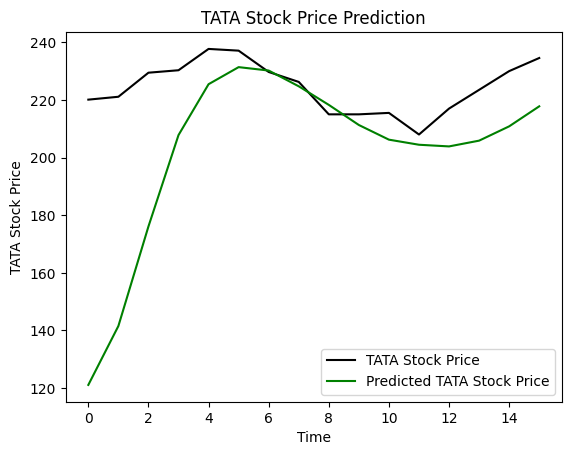

In [5]:
url = 'https://raw.githubusercontent.com/mwitiderrick/stockprice/master/tatatest.csv'
dataset_test = pd.read_csv(url)
real_stock_price = dataset_test.iloc[:, 1:2].values
dataset_total = pd.concat((dataset_train['Open'], dataset_test['Open']), axis = 0)
inputs = dataset_total[len(dataset_total) - len(dataset_test) - 60:].values
inputs = inputs.reshape(-1,1)
inputs = sc.transform(inputs)
X_test = []
for i in range(60, 76):
    X_test.append(inputs[i-60:i, 0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
# Prediction
predicted_stock_price = model.predict(X_test)
predicted_stock_price = sc.inverse_transform(predicted_stock_price)
plt.plot(real_stock_price, color = 'black', label = 'TATA Stock Price')
plt.plot(predicted_stock_price, color = 'green', label = 'Predicted TATA Stock Price')
plt.title('TATA Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('TATA Stock Price')
plt.legend()
plt.show()
print()

#  save the model

In [ ]:
#model.save('tata_model.h5')